# M5.9 · 规模容量曲线

> 策略规模越大，参与率越高、市场冲击越重，净收益被逐步侵蚀。容量曲线刻画 AUM 与净收益/净 Sharpe 的关系，确定策略可承载的规模。

## 一、机制

- 参与率 $= AUM\times\text{换手}/\text{市场年可承接量}$；
- 单次冲击 $=k\times$ 参与率，年化冲击成本 $=$ 单次冲击 × 换手；
- 净 alpha $=$ 毛 alpha $-$ 固定成本 $-$ 冲击成本；
- 冲击随规模线性上升，净 alpha 随规模下降；**盈亏平衡容量**为净 alpha 降到 0 的规模。

## 二、容量曲线

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
from bt_lab2 import capacity as cap
aum_grid = np.linspace(1e8, 5e9, 20)
cc = cap.capacity_curve(aum_grid, gross_alpha=0.15, turnover=8, adv_annual=2e10,
                        k=0.1, fixed_cost=0.02, gross_sharpe=2.0)
be = cap.breakeven_capacity(0.15, 8, 2e10, 0.1, 0.02)
print('小规模净alpha=%.4f，大规模净alpha=%.4f' % (cc['net_alpha'].iloc[0], cc['net_alpha'].iloc[-1]))
print('盈亏平衡容量=%.2f 亿元' % (be/1e8))
print(cc[['aum', 'impact_cost', 'net_alpha', 'net_sharpe']].round(4).head(5))

小规模净alpha=0.0980，大规模净alpha=-1.4700
盈亏平衡容量=4.06 亿元
            aum  impact_cost  net_alpha  net_sharpe
0  1.000000e+08       0.0320     0.0980      1.3067
1  3.578947e+08       0.1145     0.0155      0.2063
2  6.157895e+08       0.1971    -0.0671     -0.8940
3  8.736842e+08       0.2796    -0.1496     -1.9944
4  1.131579e+09       0.3621    -0.2321     -3.0947


## 三、可视化

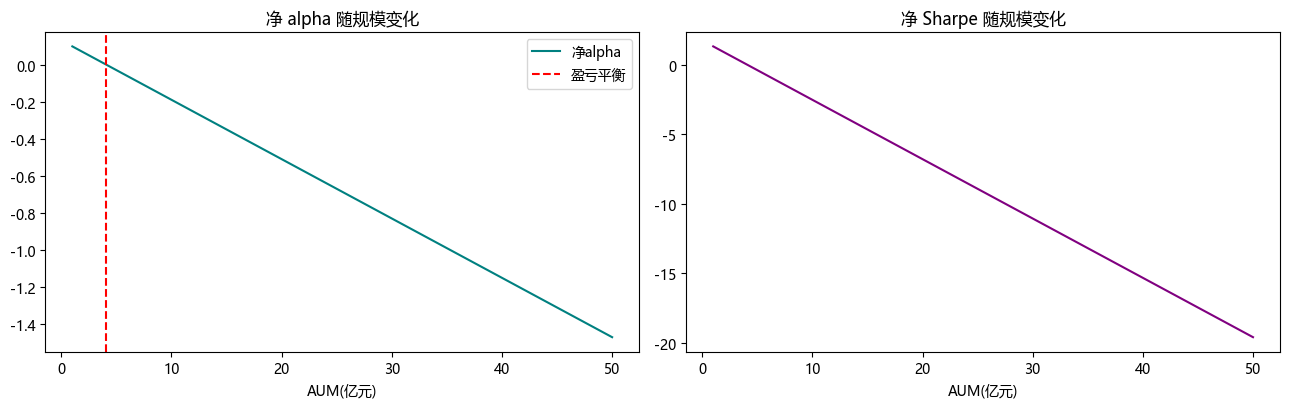

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(cc['aum']/1e8, cc['net_alpha'], color='teal', label='净alpha')
ax[0].axvline(be/1e8, color='red', ls='--', label='盈亏平衡')
ax[0].set_title('净 alpha 随规模变化'); ax[0].set_xlabel('AUM(亿元)'); ax[0].legend()
ax[1].plot(cc['aum']/1e8, cc['net_sharpe'], color='purple')
ax[1].set_title('净 Sharpe 随规模变化'); ax[1].set_xlabel('AUM(亿元)')
plt.tight_layout(); plt.show()

## 四、面试要点

- **策略容量由什么决定？** 市场流动性（ADV）、换手率、冲击系数与毛 alpha；流动性越差、换手越高，容量越小。
- **盈亏平衡容量怎么定义？** 冲击成本上升到使净 alpha 恰好为 0 的规模；实务常以净 Sharpe 降到某阈值（如 1）为可用容量。
- **为什么容量是机构选策略的关键？** 小资金高收益无法放大，机构需要在目标规模下仍有足够净收益的策略。
- **如何提升容量？** 降低换手、扩大标的池、优化执行降低冲击、用更长周期的慢因子。

## 五、练习

1. 把冲击改为平方根模型，重画容量曲线。
2. 降低换手率，观察盈亏平衡容量如何变化。
3. 用真实 ADV 估计小市值策略的实际容量。
4. 定义「净 Sharpe=1」对应的容量并求解。